# Chaining indices, classification and filtering in a tile graph

*Section 9 — Tile-graph workflows, notebook 1 of 1.* Previous: `08_hydrology/01_hydrological_analysis`. Next: `10_case_study_icesat2_bathymetry/01_visualise_icesat2`.

**You will learn:**
- why chaining operations in memory with a tile graph saves disk space and time, and when it helps;
- how to build a graph from sources, node builders (spectral indices, filters, prediction, majority filter) and sinks, and how to check it with `describe()`;
- how to give stacked feature bands unique names and one no data value with `StackBands` and `SetBandNames`;
- how to collect training samples with a `SampleSink`, so that the features are never written to disk;
- how to classify, filter and write a class map (a thematic image with class names and colours, from a `DiskSink`), the unfiltered map and the indices in one pass, with class areas from a `StatsSink` and per-class statistics from a `ZonalStatsSink`;
- how to check that a graph gives the same result as the file-based functions (`are_imgs_equal`), and how much faster it runs with `n_jobs`.

**Before you start:** `04_image_classification/03_supervised_pixel_classification` (training samples, a random forest and applying it to an image) and `04_image_classification/01_rule_based_classification` (spectral indices, colour tables and thematic maps).

**Data:** `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif` (Sentinel-2, 20 m), its valid-pixel mask `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_vmsk.tif` and the training polygons `../data/cls_data/aber_sen2_cls_training.gpkg` (one layer per class).

**Run time:** about 2 minutes.

## Introduction

Most raster workflows are chains of steps. In section 4 we calculated spectral indices, wrote them to a file, extracted training samples from the image and the indices, applied a classifier, which read them again and wrote a class map, and would then have filtered that map, writing another file. Every step writes an image that the next step reads again. For one Sentinel-2 tile that is fine, but on large images (or many of them) the intermediate files take a lot of disk space, and on slow or network disks reading and writing them can take longer than the calculations.

A **tile graph** (`rsgispy.imageprocess.TileGraph`) runs the whole chain *tile by tile in memory* and writes only the outputs you ask for. It is made of three kinds of node:

* **sources** read a raster (`RasterSource`) or a NumPy array (`ArraySource`);
* **operations** compute a new raster from one or more inputs: spectral indices, filters, a classifier, ...;
* **sinks** consume a node: write it to a file (`DiskSink`), return it as an array (`MemorySink`), collect training samples (`SampleSink`) or accumulate statistics (`StatsSink`, `ZonalStatsSink`).

When the graph runs, the image is split into tiles (256 x 256 pixels by default). For each tile every source reads its pixels, every operation computes its result from its inputs' tiles and every sink receives its tile. Only a few tiles are in memory at any time, so a graph runs on images much larger than the computer's memory, and the tiles can be processed in parallel. A moving-window operation, such as a 5 x 5 filter, needs pixels from outside the tile; the graph works out this *halo* for every node and reads the sources with it, so the result is identical to running the steps one after another on the whole image.

In this notebook we build this workflow:

```text
   Sentinel-2 image          training polygons (rasterised once)
         │                              │
   RasterSource ──► indices ──► NDVI texture                 │
         │             │            │                        │
         └──────► StackBands (features, 17 named bands) ─────┤
                       │                                     │
     graph 1:          └──────────────────────────► SampleSink ──► train a random forest
                       │
     graph 2:   predict_raster_node ──► majority_filter_node ──► DiskSink (filtered class map)
                       │                        │          └──► StatsSink, ZonalStatsSink
                       ├──► DiskSink (raw class map), StatsSink
                indices ──► DiskSink (indices)
```

The steps are:

 * Defining the sources and the feature nodes (bands, indices and a texture)
 * Collecting training samples with a `SampleSink` (graph 1)
 * Training a random forest classifier
 * Classifying, filtering and writing the outputs in one pass (graph 2)
 * Comparing the filtered and unfiltered maps, and a sieve filter (which cannot be chained)
 * Checking the graph against the file-based functions, and timing it with `n_jobs`

> **RSGISLib users:** RSGISLib has no equivalent of the tile graph; each function reads and writes files (via RIOS for the custom block-processing functions). rsgispy's file-based functions are themselves small tile graphs (`RasterSource` → node → `DiskSink`), so everything in this notebook uses the same calculations as the functions you used in the earlier sections.

## Running the notebook

The notebook has been run and saved with its outputs, so you can see what the outputs should look like and browse it online without running it.

If you run the notebook yourself, it is a good idea to clear the stored outputs first: in JupyterLab use *Edit > Clear Outputs of All Cells*, or in the classic Notebook *Cell > All Output > Clear*.

# 1. Import modules

In [1]:
# Import modules from python standard library
import os
import time

# Import numpy, pandas and geopandas for arrays, tables and vector data
import geopandas
import numpy
import pandas
import rasterio

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline
import matplotlib.pyplot as plt

# The tile graph classes (sources, band nodes, sinks and the graph)
import rsgispy
from rsgispy.imageprocess import (
    DiskSink,
    RasterSource,
    SampleSink,
    SelectBands,
    SetBandNames,
    StackBands,
    StatsSink,
    TileGraph,
    ZonalStatsSink,
    infer_node_meta,
)

# The node builders: the in-memory versions of rsgispy functions
from rsgispy.classification.classpostprocess import (
    apply_majority_filter,
    apply_sieve_filter,
    majority_filter_node,
)
from rsgispy.imagecalc.calcindices import calc_indices, calc_indices_node
from rsgispy.imagefilter.stats import apply_stddev_filter, stddev_filter_node
from rsgispy.ml.predict import predict_raster, predict_raster_node
from rsgispy.ml.stack import BandSpec

# Other rsgispy functions
import rsgispy.mapping.layout as map_layout
from rsgispy.classification.classdata import split_class_samples
from rsgispy.imagecalc.comparison import are_imgs_equal
from rsgispy.imageutils.colourtable import get_thematic_classes, set_thematic_classes
from rsgispy.imageutils.rasterise import rasterise_vec_lyr
from rsgispy.mapping.raster import create_thematic_raster_map
from rsgispy.tools.plotting import plot_feature_importance_bars

# scikit-learn imports
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, cohen_kappa_score

## 1.1 Define the inputs, outputs and classes

The inputs are the same as in `04_image_classification/03_supervised_pixel_classification`, and so are the classes: for each class, its output pixel value (class ID), the layer of the training polygons and a colour.

In [2]:
# Input Sentinel-2 image file with 20 m resolution pixels.
input_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif"

# The valid pixel mask (1 = valid) for the input image.
in_msk_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_vmsk.tif"

# The training polygons, one layer per class.
vec_train_file = "../data/cls_data/aber_sen2_cls_training.gpkg"

# All the outputs of this notebook are written to this directory.
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

# class name: (output pixel value, vector layer, (red, green, blue))
classes = {
    "Artificial_Surfaces": (1, "Artificial_Surfaces", (180, 180, 180)),
    "Bare_Rock_Sand": (2, "Bare_Rock_Sand", (131, 250, 252)),
    "Conifer_Forest": (3, "Conifer_Forest", (0, 105, 16)),
    "Deciduous_Forest": (4, "Deciduous_Forest", (62, 168, 78)),
    "Grass_Long": (5, "Grass_Long", (247, 176, 32)),
    "Grass_Short": (6, "Grass_Short", (252, 231, 109)),
    "NonPhoto_Veg": (7, "NonPhotosynthetic_Vegetation", (156, 255, 215)),
    "Scrub": (8, "Scrub", (225, 114, 247)),
    "Water": (9, "Water_Training", (0, 0, 255)),
    "Bracken": (10, "Bracken", (140, 255, 0)),
}

# Look-up tables used below: {class ID: name} and {class ID: (name, colour)}
# for the class maps and their legends.
cls_names = {cls_id: name for name, (cls_id, lyr, clr) in classes.items()}
cls_info = {cls_id: (name, clr) for name, (cls_id, lyr, clr) in classes.items()}

# 2. Sources and node metadata

A `RasterSource` reads the bands of a file: all of them, or the 1-based `bands` you give. It reads them as `float64` by default. Nothing is read yet: creating a node only describes what will be calculated when a graph runs.

Every node carries metadata (a `NodeMeta`): the number of bands, their names, the data type and the no data value. `infer_node_meta` shows it for any node. The builders and sinks use it: for example, a filter skips its input's no data pixels, and a `DiskSink` writes the band names and no data value of its input.

In [3]:
s2 = RasterSource(input_img, name="s2")
print(infer_node_meta(s2))

NodeMeta(n_bands=10, band_names=('Blue', 'Green', 'Red', 'RE_B5', 'RE_B6', 'RE_B7', 'NIR_B8', 'NIR_B8A', 'SWIR1', 'SWIR2'), dtype=dtype('float64'), nodata=0.0)


The Sentinel-2 image has 10 bands, with the band names stored in the file, and a no data value of 0.

# 3. Building the feature nodes

## 3.1 Spectral indices

Almost every rsgispy operation whose output pixel depends only on input pixels within a fixed distance has a **node builder**: a function that takes input nodes and the processing parameters and returns a node. Its name is the file-based function's name (without any `apply_` prefix) plus `_node`, so `calc_indices` becomes `calc_indices_node`, `apply_median_filter` becomes `median_filter_node` and `predict_raster` becomes `predict_raster_node`. The file-based functions build `RasterSource` → builder → `DiskSink` and run the graph, so a builder in your own graph gives exactly the same result as its function.

`calc_indices_node` takes the same arguments as `calc_indices` (notebook `04_image_classification/01_rule_based_classification`): a mapping of band numbers to the band names the index equations use, and the list of indices. We calculate six indices which help separate the classes:

* `NDVI` (red, NIR) — vegetation greenness;
* `NDWI` (green, NIR) and `MNDWI` (green, SWIR1) — open water;
* `NDBI` (NIR, SWIR1) — built-up areas and bare ground;
* `NBR` (NIR, SWIR2) — vegetation moisture and non-photosynthetic vegetation;
* `NDRE` (red edge, NIR) — canopy chlorophyll, which differs between the forest types.

`get_index_req_bands` lists the bands an index needs. All these indices are ratios, so the reflectance scaling (x 1000 in this image) does not matter.

In [4]:
# Band number in the image: name used by the index equations.
s2_band_names = {
    1: "blue",
    2: "green",
    3: "red",
    4: "red_edge",  # band 5 (705 nm)
    7: "nir",  # band 8
    9: "swir1",  # band 11
    10: "swir2",  # band 12
}
index_names = ["NDVI", "NDWI", "MNDWI", "NDBI", "NBR", "NDRE"]

indices = calc_indices_node(s2, s2_band_names, index_names, name="indices")
print(infer_node_meta(indices))

NodeMeta(n_bands=6, band_names=('NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NBR', 'NDRE'), dtype=dtype('float32'), nodata=-999.0)


The indices node has one `float32` band per index, named after the index, with a no data value of -999 (where any input band was no data).

## 3.2 A texture: the local variation of the NDVI

Classes such as conifer and deciduous forest, or long grass and scrub, can have similar spectra but a different spatial pattern. A simple texture feature is the standard deviation of the NDVI in a 5 x 5 window. `SelectBands` picks the NDVI (band 1) from the indices, and `stddev_filter_node` (the node of `apply_stddev_filter`) filters it. This is a moving-window operation, so the graph will read a halo of 2 pixels around each tile.

A filter keeps its input's band names, so the texture band would also be called `NDVI`. Two bands with the same name would be confusing (and a `SampleSink` raises an error for repeated names, as the names become the columns of the sample table), so `SetBandNames` renames it. (`SelectBands` and `StackBands` also take `band_names`.)

In [5]:
ndvi = SelectBands(indices, 1)
ndvi_sd = SetBandNames(stddev_filter_node(ndvi, 5), ["NDVI_sd5"])
print(infer_node_meta(ndvi_sd))

NodeMeta(n_bands=1, band_names=('NDVI_sd5',), dtype=dtype('float64'), nodata=-999.0)


## 3.3 Stack the features

`StackBands` stacks the bands of several nodes, keeping their names. The features for the classifier are the 10 reflectance bands, the 6 indices and the texture: 17 bands, each with a unique name. The order of the bands is the order of the classifier's features, and the same node will be used both for the training samples and for the classification, so they cannot get out of step.

A stack has one no data value for all its bands, but our inputs have different ones: 0 for the Sentinel-2 bands and -999 for the indices and the texture. Without `no_data_val` the stack would have no no data value at all (and `StackBands` warns about it), so the sinks and the classifier would treat a no data pixel of any input as valid data. With `no_data_val=-999`, every band of a pixel where any input is no data is set to -999, which is the stack's no data value. A pixel invalid in any feature is then skipped when the samples are collected and when the image is classified. (-999 cannot be a valid value of any of the bands: the reflectances are positive and the indices are between -1 and 1.)

In [6]:
features = StackBands([s2, indices, ndvi_sd], name="features", no_data_val=-999)
feat_meta = infer_node_meta(features)
feat_names = list(feat_meta.band_names)
print(len(feat_names), feat_names)
print(f"No data value: {feat_meta.nodata}")

17 ['Blue', 'Green', 'Red', 'RE_B5', 'RE_B6', 'RE_B7', 'NIR_B8', 'NIR_B8A', 'SWIR1', 'SWIR2', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NBR', 'NDRE', 'NDVI_sd5']
No data value: -999.0


Still nothing has been read or calculated: `features` is a description of a calculation, and it can be used by several later nodes and in several graphs.

# 4. Training samples from the graph

## 4.1 Rasterise the training polygons

A `SampleSink` collects the feature values of the labelled pixels: it needs a raster of class IDs on the same pixel grid as the features, with 0 for unlabelled pixels. The training polygons are in one layer per class, so we combine them into one GeoDataFrame with a class ID column and rasterise it once onto the grid of the Sentinel-2 image with `rasterise_vec_lyr`. This is a small `uint8` file, and it is an input to the graph, not an intermediate product.

(In `04_image_classification/03_supervised_pixel_classification`, `extract_class_training_samples` did this rasterising internally.)

In [7]:
train_gdfs = list()
for cls_name, (cls_id, lyr_name, clr) in classes.items():
    lyr_gdf = geopandas.read_file(vec_train_file, layer=lyr_name)
    lyr_gdf["cls_id"] = cls_id
    train_gdfs.append(lyr_gdf[["cls_id", "geometry"]])
train_gdf = geopandas.GeoDataFrame(
    pandas.concat(train_gdfs, ignore_index=True), crs=train_gdfs[0].crs
)
print(f"{len(train_gdf)} training polygons")

train_lbls_img = os.path.join(out_dir, "training_labels.tif")
rasterise_vec_lyr(
    train_gdf, None, input_img, train_lbls_img, att_column="cls_id", use_pbar=False
)

351 training polygons


## 4.2 Collect the samples with a `SampleSink`

The first graph has a single sink. The `SampleSink` takes the feature node and the label node (a `RasterSource` of the rasterised polygons, whose no data value of 0 marks the unlabelled pixels). With `max_per_class` it keeps a random sample of at most that many pixels per class while the graph runs, so the memory used stays small however large the image is; the sample is the same for any block size and `n_jobs` (`rnd_seed` chooses another one). `class_names` gives the names for the `class_name` column.

`describe()` prints the graph before it runs: the pixel grid, the block size and every node with its inputs, parameters, halo and metadata. Note that the Sentinel-2 source is read with a halo of 2 pixels, for the 5 x 5 texture.

In [8]:
train_lbls = RasterSource(train_lbls_img, name="labels")
smpls_graph = TileGraph(
    SampleSink(
        features,
        train_lbls,
        max_per_class=1000,
        class_names=cls_names,
        rnd_seed=42,
        name="samples",
    )
)
print(smpls_graph.describe())

TileGraph: 9 node(s), 1 sink(s), block_size=256
  grid: 2880 rows x 3295 columns, crs=EPSG:27700, transform=(20.0, 0.0, 249177.3321426216, 0.0, -20.0, 326342.255157026)
  [0] RasterSource 'labels' (path='outputs/training_labels.tif' bands=all)
      halo=(0, 0) radius=(0, 0) bands=1 dtype=float64 nodata=0.0
  [1] RasterSource 's2' (path='../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif' bands=all)
      halo=(2, 2) radius=(0, 0) bands=10 names=['Blue', 'Green', 'Red', 'RE_B5', 'RE_B6', 'RE_B7', 'NIR_B8', 'NIR_B8A', 'SWIR1', 'SWIR2'] dtype=float64 nodata=0.0
  [2] IndicesNode 'indices' <- [1] (indices=['NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NBR', 'NDRE'] dtype=float32)
      halo=(2, 2) radius=(0, 0) bands=6 names=['NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NBR', 'NDRE'] dtype=float32 nodata=-999.0
  [3] SelectBands <- [2] (bands=[1])
      halo=(2, 2) radius=(0, 0) bands=1 names=['NDVI'] dtype=float32 nodata=-999.0
  [4] FilterWindowOp 'stddev_filter' <- [3] (radius=(2, 2) border=edge)
     

`run()` processes the tiles and returns a dictionary of the sinks' results, under their names:

In [9]:
smpls_df = smpls_graph.run(use_pbar=False)["samples"]
smpls_df.head()

,class_name,out_cls_id,internal_cls_id,x,y,Blue,Green,Red,RE_B5,RE_B6,...,NIR_B8A,SWIR1,SWIR2,NDVI,NDWI,MNDWI,NDBI,NBR,NDRE,NDVI_sd5
0,Artificial_Surfaces,1,0,264627.332143,284332.255157,82.0,103.0,109.0,147.0,236.0,...,285.0,252.0,181.0,0.421751,-0.444744,-0.419718,-0.030769,0.193764,0.291566,0.148875
1,Artificial_Surfaces,1,0,264607.332143,284312.255157,84.0,99.0,107.0,147.0,230.0,...,273.0,257.0,181.0,0.390313,-0.422741,-0.443820,0.025948,0.148235,0.248082,0.143778
2,Artificial_Surfaces,1,0,264627.332143,284312.255157,83.0,103.0,113.0,150.0,234.0,...,281.0,252.0,184.0,0.392473,-0.430939,-0.419718,-0.013699,0.169300,0.266504,0.129254
3,Artificial_Surfaces,1,0,264847.332143,284272.255157,87.0,97.0,101.0,143.0,204.0,...,235.0,221.0,160.0,0.344156,-0.361842,-0.389937,0.032710,0.128065,0.182857,0.120410
4,Artificial_Surfaces,1,0,264867.332143,284272.255157,81.0,95.0,95.0,140.0,206.0,...,237.0,222.0,158.0,0.387097,-0.387097,-0.400631,0.016018,0.152815,0.211268,0.121428


The table has the same layout as the sample tables of `extract_class_training_samples`: the class name, the output and internal class IDs, the pixel coordinates and one column per feature band, named after the band names we gave the nodes. The features (17 bands for 9.5 million pixels, about 1.3 GB as `float64`) were never written to disk or held in memory as a whole.

In [10]:
smpls_df["class_name"].value_counts()

class_name
Bare_Rock_Sand         1000
Conifer_Forest         1000
Deciduous_Forest       1000
Grass_Long             1000
NonPhoto_Veg           1000
Scrub                  1000
Water                  1000
Bracken                1000
Grass_Short             622
Artificial_Surfaces     454
Name: count, dtype: int64

# 5. Train the classifier

As in section 4, the smallest class (Artificial_Surfaces) sets the number of samples per class: 350 for training, 50 for validation and 50 for testing, selected at random with `split_class_samples`, which works on the `SampleSink` table directly.

> **Spatial autocorrelation:** as in `04_image_classification/03_supervised_pixel_classification`, the pixels are split at random, so pixels of the same polygon are in all three sets and the accuracies will be optimistic.

We use a random forest with the parameters close to those found by the grid search in section 4. Its `n_jobs` is 1 because the graph will run the tiles in parallel (section 10); using both would compete for the same CPU cores.

In [11]:
train_df, test_df, valid_df = split_class_samples(
    smpls_df, n_train=350, n_valid=50, n_test=50, rnd_seed=42
)
print(f"Training: {len(train_df)}, validation: {len(valid_df)}, testing: {len(test_df)}")

rf_clf = RandomForestClassifier(
    n_estimators=100, max_depth=12, random_state=42, n_jobs=1
)
rf_clf.fit(train_df[feat_names].to_numpy(), train_df["out_cls_id"].to_numpy())

acc_rows = dict()
for set_name, set_df in [("validation", valid_df), ("testing", test_df)]:
    ref = set_df["out_cls_id"].to_numpy()
    pred = rf_clf.predict(set_df[feat_names].to_numpy())
    acc_rows[set_name] = {
        "accuracy": accuracy_score(ref, pred),
        "balanced_accuracy": balanced_accuracy_score(ref, pred),
        "kappa": cohen_kappa_score(ref, pred),
    }
pandas.DataFrame(acc_rows).T.round(3)

Training: 3500, validation: 500, testing: 500


,accuracy,balanced_accuracy,kappa
validation,0.986,0.986,0.984
testing,0.992,0.992,0.991


Which features does the random forest use most? The feature importances show whether the indices and the texture were worth adding. `plot_feature_importance_bars` draws them sorted, the most important at the top; the error bars are the standard deviation of the importances of the individual trees of the forest. Each tree is trained on a random sample of the pixels and chooses from a random subset of the features at each split, so the trees use the features very differently; it is the forest's average which is meaningful:

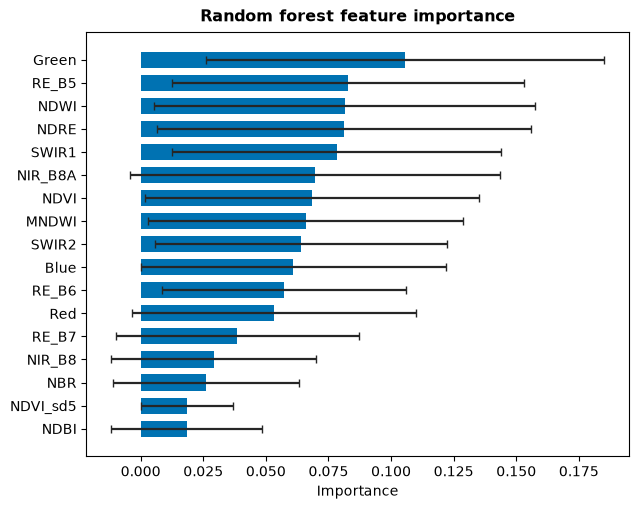

In [12]:
tree_imps = numpy.array([tree.feature_importances_ for tree in rf_clf.estimators_])
fig, ax = plt.subplots(figsize=(7, 5.5))
_ = plot_feature_importance_bars(
    feat_names,
    rf_clf.feature_importances_,
    errors=tree_imps.std(axis=0),
    title="Random forest feature importance",
    ax=ax,
)

# 6. Classify, filter and write in one pass

## 6.1 Build the classification graph

The second graph uses the same `features` node:

* `predict_raster_node` applies the random forest to every pixel inside the valid mask (`mask`, pixels with a value of 1) where all the features are valid (not the stack's no data value, -999). The valid mask and the no data rule of the stack work together: the mask marks the area to classify, and the no data rule skips any pixel within it where one of the inputs has no data. With `thematic=True` the other pixels are 0 and, as every class fits, the result is `uint8`.
* A per-pixel classification is often noisy: single pixels of one class inside another ("salt and pepper"). `majority_filter_node` (the node of `apply_majority_filter`) replaces each pixel by the most common class in a 5 x 5 window; with `dtype=numpy.uint8` its result is `uint8` too.

The sinks are:

* three `DiskSink`s, for the filtered class map, the raw (unfiltered) class map and the indices. Without `datatype`, a `DiskSink` writes the data type of its input node (`uint8` for the class maps, `float32` for the indices), with its band names and no data value. The class maps are written as thematic images (`thematic=True`), with the class names and colours (`classes`, `{class ID: (name, colour)}`) and their statistics and pyramids;
* two `StatsSink`s, which count the pixels of each class in the raw and filtered maps: with `bins` set to the edges between the class IDs, the histogram is the number of pixels per class;
* a `ZonalStatsSink`, which calculates the statistics of the indices for every class of the filtered map.

So in one pass over the image the graph reads the image once, and calculates the indices, the texture, the classification and the filter once, for six outputs. Run as separate functions this would be six passes, with the indices, the texture, the features and the raw map written and read again.

In [13]:
valid_msk = RasterSource(in_msk_img, name="valid_mask")
cls_raw = predict_raster_node(features, rf_clf, thematic=True, mask=valid_msk)
cls_maj = majority_filter_node(cls_raw, 5, dtype=numpy.uint8)

cls_raw_img = os.path.join(out_dir, "sen2_20180629_aber_cls_raw.tif")
cls_maj_img = os.path.join(out_dir, "sen2_20180629_aber_cls_maj5.tif")
indices_img = os.path.join(out_dir, "sen2_20180629_aber_indices.tif")

# Bin edges half way between the class IDs (0.5, 1.5, ..., 10.5), so each
# histogram bin counts the pixels of one class.
cls_bins = numpy.arange(0.5, len(classes) + 1, 1.0)

cls_graph = TileGraph(
    [
        DiskSink(cls_maj, cls_maj_img, thematic=True, classes=cls_info),  # uint8
        DiskSink(cls_raw, cls_raw_img, thematic=True, classes=cls_info),  # uint8
        DiskSink(indices, indices_img, calc_stats=True),  # float32, band names
        StatsSink(cls_raw, bins=cls_bins, name="raw_counts"),
        StatsSink(cls_maj, bins=cls_bins, name="maj_counts"),
        ZonalStatsSink(cls_maj, indices, name="cls_indices"),
    ]
)
print(cls_graph.describe())

TileGraph: 17 node(s), 6 sink(s), block_size=256
  grid: 2880 rows x 3295 columns, crs=EPSG:27700, transform=(20.0, 0.0, 249177.3321426216, 0.0, -20.0, 326342.255157026)
  [0] RasterSource 's2' (path='../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif' bands=all)
      halo=(4, 4) radius=(0, 0) bands=10 names=['Blue', 'Green', 'Red', 'RE_B5', 'RE_B6', 'RE_B7', 'NIR_B8', 'NIR_B8A', 'SWIR1', 'SWIR2'] dtype=float64 nodata=0.0
  [1] IndicesNode 'indices' <- [0] (indices=['NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NBR', 'NDRE'] dtype=float32)
      halo=(4, 4) radius=(0, 0) bands=6 names=['NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NBR', 'NDRE'] dtype=float32 nodata=-999.0
  [2] SelectBands <- [1] (bands=[1])
      halo=(4, 4) radius=(0, 0) bands=1 names=['NDVI'] dtype=float32 nodata=-999.0
  [3] FilterWindowOp 'stddev_filter' <- [2] (radius=(2, 2) border=edge)
      halo=(2, 2) radius=(2, 2) bands=1 names=['NDVI'] dtype=float64 nodata=-999.0
  [4] SetBandNames <- [3] (band_names=['NDVI_sd5'])
      hal

Read the description from the top: the Sentinel-2 source is read with a halo of 4 pixels, 2 for the 5 x 5 texture plus 2 for the 5 x 5 majority filter after the prediction. The majority filter is a `WindowOp` followed by a `Cast` to `uint8`, and the `DiskSink`s show the data type they will write.

## 6.2 Run the graph

`n_jobs=-1` processes the tiles on all the CPU cores (section 10 compares the times).

In [14]:
t_start = time.perf_counter()
cls_res = cls_graph.run(use_pbar=False, n_jobs=-1)
print(f"Classification graph: {time.perf_counter() - t_start:.1f} s")
print(list(cls_res.keys()))

Classification graph: 11.9 s
['raw_counts', 'maj_counts', 'cls_indices']


The `DiskSink`s return nothing (their outputs are the files); the statistics sinks return their results.

## 6.3 The class maps are thematic

With `thematic=True` and `classes`, the `DiskSink`s wrote the class maps as thematic images, with the class colours in the colour table and the class names stored in the file, as `set_thematic_classes` does (`04_image_classification/01_rule_based_classification`). So nothing has to be added to the files after the graph has run, and the maps and legends below find the class names in the files. `get_thematic_classes` reads them back:

> **RSGISLib users:** there is no raster attribute table; the class names are stored in the GeoTIFF as a band tag, where the rsgispy mapping functions read them.

In [15]:
get_thematic_classes(cls_maj_img)

{1: ('Artificial_Surfaces', '#b4b4b4'),
 2: ('Bare_Rock_Sand', '#83fafc'),
 3: ('Conifer_Forest', '#006910'),
 4: ('Deciduous_Forest', '#3ea84e'),
 5: ('Grass_Long', '#f7b020'),
 6: ('Grass_Short', '#fce76d'),
 7: ('NonPhoto_Veg', '#9cffd7'),
 8: ('Scrub', '#e172f7'),
 9: ('Water', '#0000ff'),
 10: ('Bracken', '#8cff00')}

# 7. Compare the filtered and unfiltered maps

## 7.1 Class areas

The `StatsSink` results are `RasterStats` objects; `hist` has the histogram of each band, here the number of pixels of each class. Each pixel is 20 x 20 m (0.04 ha), so the areas follow directly, without reading the class maps again:

In [16]:
pxl_area_ha = 20 * 20 / 10000

raw_counts = cls_res["raw_counts"].hist[0]
maj_counts = cls_res["maj_counts"].hist[0]
area_df = pandas.DataFrame(
    {
        "raw_pixels": raw_counts,
        "maj5_pixels": maj_counts,
        "raw_area_ha": raw_counts * pxl_area_ha,
        "maj5_area_ha": maj_counts * pxl_area_ha,
    },
    index=pandas.Index([cls_names[i] for i in range(1, len(classes) + 1)], name="class"),
)
area_df["change_pct"] = 100 * (area_df["maj5_pixels"] / area_df["raw_pixels"] - 1)
area_df.round(1)

,raw_pixels,maj5_pixels,raw_area_ha,maj5_area_ha,change_pct
class,,,,,
Artificial_Surfaces,183832,150309,7353.3,6012.4,-18.2
Bare_Rock_Sand,122559,122140,4902.4,4885.6,-0.3
Conifer_Forest,529171,554062,21166.8,22162.5,4.7
Deciduous_Forest,1200206,1244202,48008.2,49768.1,3.7
Grass_Long,1273948,1190683,50957.9,47627.3,-6.5
Grass_Short,2712332,2936375,108493.3,117455.0,8.3
NonPhoto_Veg,231055,227184,9242.2,9087.4,-1.7
Scrub,1322821,1194942,52912.8,47797.7,-9.7
Water,1285657,1287064,51426.3,51482.6,0.1


The total area does not change (the majority filter only reclassifies valid pixels), but the classes do: classes which are often found as scattered single pixels lose area to the classes around them. Which classes lose most, and does that make sense from what you know about them?

How many pixels did the filter change? This time we read the two maps:

In [17]:
with rasterio.open(cls_raw_img) as raw_ds, rasterio.open(cls_maj_img) as maj_ds:
    raw_arr = raw_ds.read(1)
    maj_arr = maj_ds.read(1)

valid = raw_arr > 0
n_changed = numpy.count_nonzero(raw_arr[valid] != maj_arr[valid])
print(f"{n_changed} of {valid.sum()} pixels changed ({100 * n_changed / valid.sum():.1f} %)")

1670535 of 9483840 pixels changed (17.6 %)


## 7.2 The indices of each class

The `ZonalStatsSink` result is a table with the count, mean, minimum, maximum and standard deviation of each index for each class of the filtered map. The mean values are a useful check of the classification: water should have a high MNDWI and negative NDVI, the forests the highest NDVI, and so on.

In [18]:
zonal_df = cls_res["cls_indices"]
mean_cols = [f"{idx}_mean" for idx in index_names]
cls_means_df = zonal_df[mean_cols].rename(columns=lambda c: c[: -len("_mean")])
cls_means_df.index = [cls_names[int(i)] for i in cls_means_df.index]
cls_means_df.round(3)

,NDVI,NDWI,MNDWI,NDBI,NBR,NDRE
Artificial_Surfaces,0.449,-0.471,-0.447,-0.040,0.206,0.298
Bare_Rock_Sand,0.034,0.010,0.144,-0.190,0.301,0.001
Conifer_Forest,0.864,-0.757,-0.450,-0.464,0.723,0.614
Deciduous_Forest,0.872,-0.785,-0.586,-0.371,0.654,0.634
Grass_Long,0.854,-0.767,-0.577,-0.342,0.622,0.604
Grass_Short,0.732,-0.695,-0.597,-0.171,0.453,0.488
NonPhoto_Veg,0.466,-0.567,-0.585,0.026,0.205,0.293
Scrub,0.742,-0.701,-0.606,-0.168,0.459,0.483
Water,-0.094,0.600,0.755,-0.314,0.231,-0.114
Bracken,0.873,-0.775,-0.576,-0.361,0.645,0.619


## 7.3 Maps

The whole classification, with a legend (of the class names stored in the file) and a north arrow:

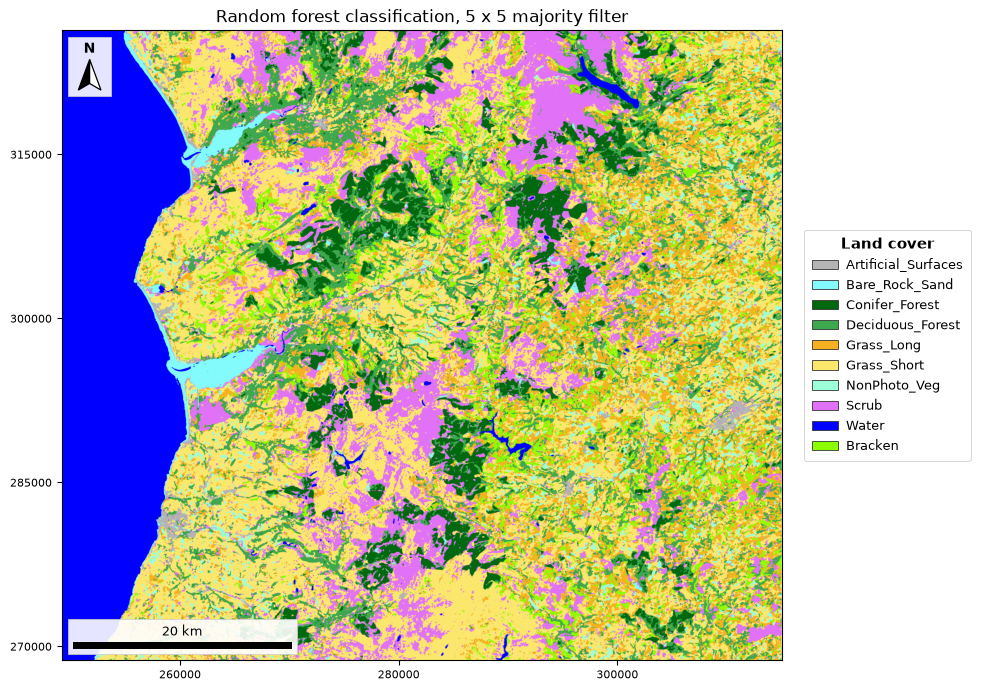

In [19]:
fig, ax = plt.subplots(figsize=(12, 10))
_ = create_thematic_raster_map(
    ax,
    cls_maj_img,
    show_scale_bar=True,
    scale_bar_loc="lower left",
    show_north_arrow=True,
    north_arrow_loc="upper left",
    show_legend=True,
    legend_title="Land cover",
)
ax.set_title("Random forest classification, 5 x 5 majority filter")
plt.show()

The effect of the filter is clearer in a subset. Here the image, the raw classification and the filtered classification are side by side for an area to the south-east of Aberystwyth, drawn with `create_map_panels`, which gives the maps the same extent and one legend for the classes of the thematic panels:

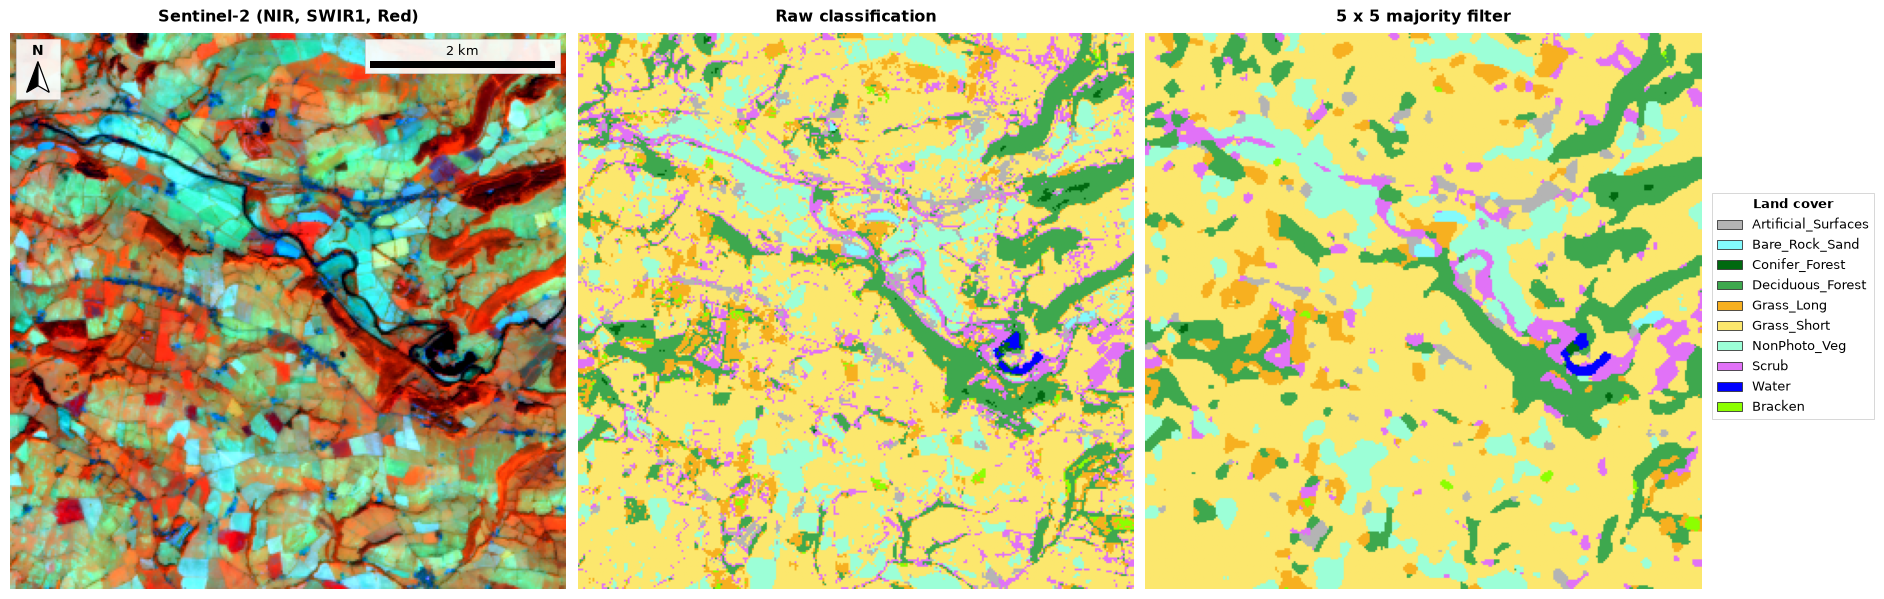

In [20]:
# A 6 x 6 km subset (xmin, xmax, ymin, ymax)
sub_img_bbox = [262000, 268000, 276000, 282000]

# The Sentinel-2 image (NIR, SWIR1, Red), as the first panel of each figure.
s2_panel = map_layout.MapPanel(
    "rgb", input_img, bands=[8, 9, 3], title="Sentinel-2 (NIR, SWIR1, Red)"
)

fig, axs = map_layout.create_map_panels(
    [
        s2_panel,
        map_layout.MapPanel("thematic", cls_raw_img, title="Raw classification"),
        map_layout.MapPanel("thematic", cls_maj_img, title="5 x 5 majority filter"),
    ],
    bbox=sub_img_bbox,
    classes_info=cls_info,
    legend_title="Land cover",
    figsize=(17, 6),
)

The majority filter removes most of the isolated pixels and smooths the boundaries between classes, which gives a map that is easier to read. It also removes small features which are real, such as narrow roads, hedgerows and streams, and rounds the corners of fields, so the filter size is a compromise; try a 3 x 3 window (section 11).

# 8. A sieve filter: an operation which cannot be chained

A different way to clean up a classification is a **sieve filter** (`apply_sieve_filter`): it finds the connected regions (clumps) of each class and merges the regions smaller than a minimum mapping unit into their neighbours. Unlike the majority filter, it removes small regions whatever their shape, and leaves the boundaries of the larger regions unchanged.

A region can be any size, so whether a pixel is in a small region cannot be decided from a fixed neighbourhood: a sieve filter has no node and cannot be part of a tile graph. The same applies to segmentation, flow accumulation and distance transforms. The rule is to run the graph up to such a step, write that output, and run the whole-image operation on the file, which is what we do here, with a minimum mapping unit of 10 pixels (0.4 ha) on the raw classification:

In [21]:
cls_sieve_img = os.path.join(out_dir, "sen2_20180629_aber_cls_sieve10.tif")
apply_sieve_filter(cls_raw_img, cls_sieve_img, size_threshold=10, connectivity=4, use_pbar=False)
# The class names and colours (the sieve filter copies the colour table only).
set_thematic_classes(cls_sieve_img, cls_info)

with rasterio.open(cls_sieve_img) as ds:
    sieve_arr = ds.read(1)
sieve_counts = numpy.bincount(sieve_arr[sieve_arr > 0], minlength=len(classes) + 1)[1:]
area_df["sieve10_pixels"] = sieve_counts
n_changed = numpy.count_nonzero(raw_arr[valid] != sieve_arr[valid])
print(f"Sieve: {n_changed} pixels changed ({100 * n_changed / valid.sum():.1f} %)")
area_df[["raw_pixels", "maj5_pixels", "sieve10_pixels"]]

Sieve: 1128298 pixels changed (11.9 %)


,raw_pixels,maj5_pixels,sieve10_pixels
class,,,
Artificial_Surfaces,183832,150309,159736
Bare_Rock_Sand,122559,122140,122804
Conifer_Forest,529171,554062,548607
Deciduous_Forest,1200206,1244202,1266275
Grass_Long,1273948,1190683,1144736
Grass_Short,2712332,2936375,2890230
NonPhoto_Veg,231055,227184,237983
Scrub,1322821,1194942,1216662
Water,1285657,1287064,1287462


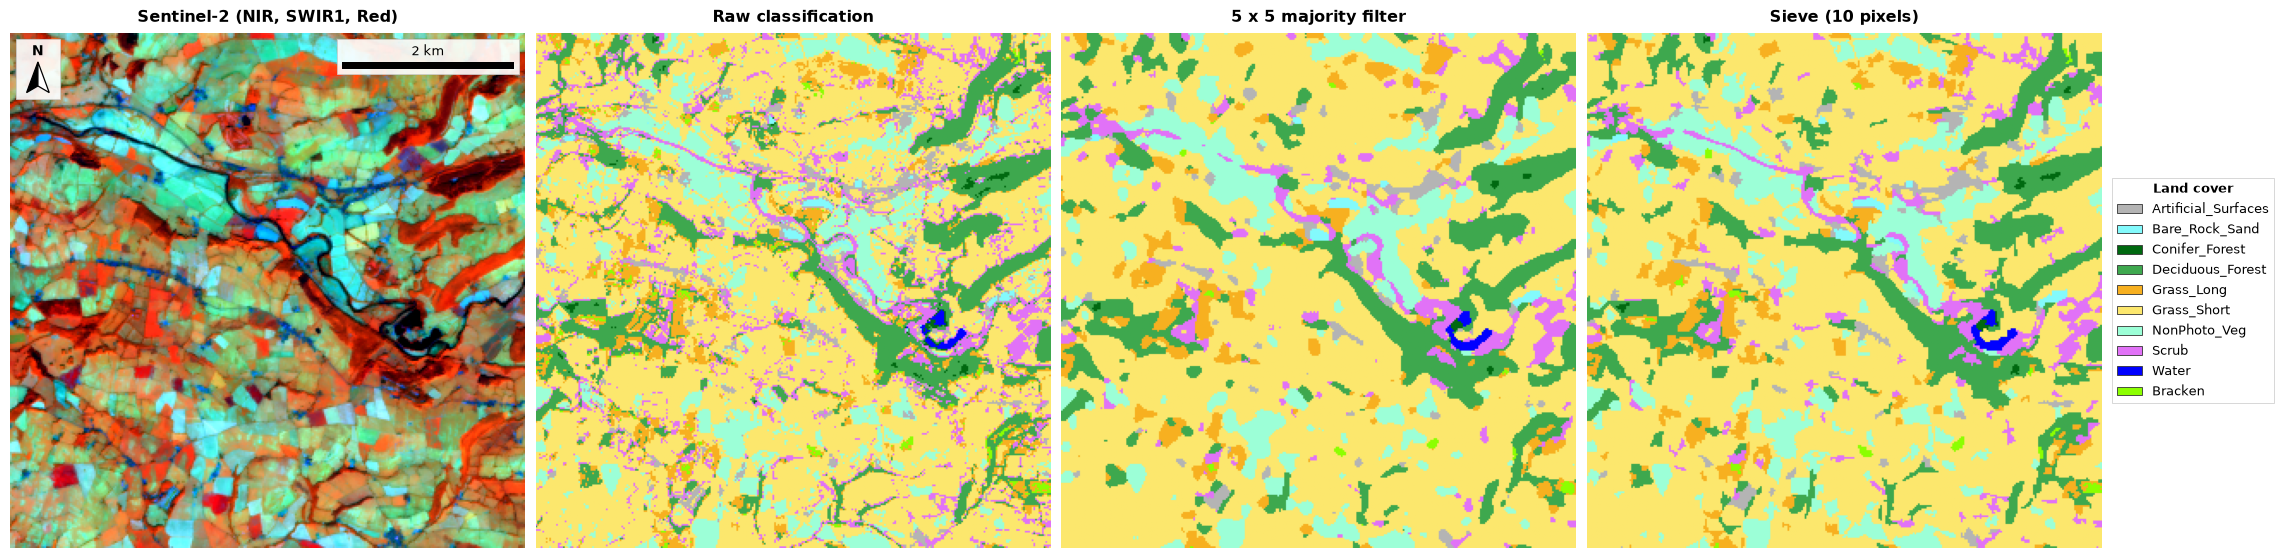

In [22]:
fig, axs = map_layout.create_map_panels(
    [
        s2_panel,
        map_layout.MapPanel("thematic", cls_raw_img, title="Raw classification"),
        map_layout.MapPanel("thematic", cls_maj_img, title="5 x 5 majority filter"),
        map_layout.MapPanel("thematic", cls_sieve_img, title="Sieve (10 pixels)"),
    ],
    bbox=sub_img_bbox,
    classes_info=cls_info,
    legend_title="Land cover",
    figsize=(21, 6),
)

The sieve removes the isolated pixels and small groups but keeps the boundaries and the narrow linear features, which are connected into large regions. It changes fewer pixels than the majority filter (compare the numbers of changed pixels above). The two can also be combined, e.g. a 3 x 3 majority filter in the graph followed by a sieve.

# 9. Does the graph give the same result as the file-based functions?

The builders are the file-based functions' own nodes, so the graph should give exactly the same result as running the functions one after another, each writing a file that the next one reads. It is worth checking your own graphs once, on a small image or a subset. Here we run the whole chain with the file-based functions (and time it for section 10):

1. `calc_indices` → indices image;
2. `apply_stddev_filter` on the indices → texture image (the filter is applied to every band, so we use only band 1, the NDVI, below);
3. `predict_raster` with a feature stack of the three images (`BandSpec` selects the bands of each) → raw class map;
4. `apply_majority_filter` → filtered class map.

In [23]:
chk_dir = os.path.join(out_dir, "file_steps")
os.makedirs(chk_dir, exist_ok=True)
f_indices_img = os.path.join(chk_dir, "indices.tif")
f_sd_img = os.path.join(chk_dir, "indices_sd5.tif")
f_cls_raw_img = os.path.join(chk_dir, "cls_raw.tif")
f_cls_maj_img = os.path.join(chk_dir, "cls_maj5.tif")

t_start = time.perf_counter()
calc_indices(input_img, f_indices_img, s2_band_names, index_names, use_pbar=False)
apply_stddev_filter(f_indices_img, f_sd_img, 5, use_pbar=False)
predict_raster(
    rf_clf,
    [
        BandSpec(input_img, name="s2"),
        BandSpec(f_indices_img, name="indices"),
        BandSpec(f_sd_img, name="ndvi_sd", bands=(1,)),
    ],
    f_cls_raw_img,
    in_msk_img=in_msk_img,
    thematic=True,
    use_pbar=False,
)
apply_majority_filter(f_cls_raw_img, f_cls_maj_img, 5, use_pbar=False)
t_files = time.perf_counter() - t_start
print(f"File-based functions: {t_files:.1f} s")

File-based functions: 41.9 s


In [24]:
# are_imgs_equal returns (equal, proportion of equal pixels); flt_dif=0
# tests for identical values.
for graph_img, file_img in [
    (indices_img, f_indices_img),
    (cls_raw_img, f_cls_raw_img),
    (cls_maj_img, f_cls_maj_img),
]:
    is_eq = are_imgs_equal(graph_img, file_img, flt_dif=0, use_pbar=False)[0]
    print(f"{os.path.basename(graph_img):40s} identical: {is_eq}")

sen2_20180629_aber_indices.tif           identical: True
sen2_20180629_aber_cls_raw.tif           identical: True
sen2_20180629_aber_cls_maj5.tif          identical: True


The outputs are identical, pixel for pixel. The file-based route had to write the indices, the texture (6 bands, about 230 MB uncompressed, although we only needed one) and the raw class map, and each step read them back. The graph wrote only the outputs we asked for; had we not wanted the indices and the raw map, it would not have written them either.

If your own graph and the step-by-step functions differ, add a `MemorySink` to the intermediate nodes and compare them step by step, and check each node's halo, band names, data type and no data value with `describe()`. (If the steps write intermediate files in a smaller data type than the graph keeps in memory, the results may differ slightly; compare them with a tolerance, `are_imgs_equal(..., flt_dif=...)`.)

# 10. Timing and `n_jobs`

`run(n_jobs=...)` evaluates the tiles on several threads (`-1` or `None` uses every CPU core; the default is 1). Each thread has its own open files, and the tiles are written in order by the main thread, so the outputs and statistics are identical for any `n_jobs`. The file-based functions always use one thread.

Let's time the classification graph with one thread and with all the cores, writing to a separate folder:

In [25]:
timing_dir = os.path.join(out_dir, "timing")
os.makedirs(timing_dir, exist_ok=True)


def time_cls_graph(n_jobs):
    # Build and run the classification graph; return the run time (s).
    graph = TileGraph(
        [
            DiskSink(cls_maj, os.path.join(timing_dir, "cls_maj5.tif"), classes=cls_info),
            DiskSink(cls_raw, os.path.join(timing_dir, "cls_raw.tif"), classes=cls_info),
            DiskSink(indices, os.path.join(timing_dir, "indices.tif")),
            StatsSink(cls_raw, bins=cls_bins, name="raw_counts"),
            StatsSink(cls_maj, bins=cls_bins, name="maj_counts"),
            ZonalStatsSink(cls_maj, indices, name="cls_indices"),
        ]
    )
    t_start = time.perf_counter()
    graph.run(use_pbar=False, n_jobs=n_jobs)
    return time.perf_counter() - t_start


n_cpus = os.cpu_count()
timings = {
    "File-based functions (1 thread)": t_files,
    "Tile graph, n_jobs=1": time_cls_graph(1),
    f"Tile graph, n_jobs=-1 ({n_cpus} cores)": time_cls_graph(-1),
}
timing_df = pandas.DataFrame({"seconds": timings})
timing_df["speed_up"] = timing_df["seconds"].iloc[0] / timing_df["seconds"]
timing_df.round(2)

,seconds,speed_up
File-based functions (1 thread),41.86,1.00
"Tile graph, n_jobs=1",33.29,1.26
"Tile graph, n_jobs=-1 (12 cores)",9.10,4.60


On one thread the graph is faster than the file-based functions, even though it also calculates the class statistics: it does not write and read the intermediate files, and it calculates the texture of the NDVI only (the file-based `apply_stddev_filter` filtered all six index bands). On a fast local disk most of the time is the calculations (mostly the random forest prediction), and the gain from avoiding intermediate files grows with slower or network disks and larger images. The large gain comes from running the tiles in parallel. (The exact times depend on your computer; the saved outputs come from a 12-core laptop.)

A few notes on the timings:

* The random forest was created with `n_jobs=1`. With the graph running the tiles in parallel, letting scikit-learn use all the cores as well for every tile would only make the threads compete.
* The majority filter uses a numba kernel, which runs in parallel itself. If numba's threading layer is `workqueue` (when neither TBB nor OpenMP is installed), these kernels run one at a time and do not speed up with `n_jobs`; installing TBB fixes that (`conda install -c conda-forge tbb`).
* A small image gives few tiles to share out; the speed-up grows with the image size.

In [26]:
import numba

print("numba threading layer:", numba.threading_layer())

numba threading layer: tbb


# 11. Summary and things to try

In this notebook we have built one in-memory chain from a Sentinel-2 image to a filtered land cover map:

 * sources, node builders and sinks, and the node metadata (band names, data types and no data values) which connects them;
 * spectral indices and a texture as nodes, stacked into named features with one no data value with `StackBands`, `SelectBands` and `SetBandNames`;
 * training samples collected tile by tile with a `SampleSink`, without writing the features;
 * one graph which classifies the image, applies a majority filter, and writes the class maps (as thematic images with class names and colours) and the indices, with the class areas (`StatsSink`) and per-class index statistics (`ZonalStatsSink`) calculated in the same pass;
 * whole-image operations, such as the sieve filter, run on a file written by the graph;
 * the graph gives exactly the same result as the file-based functions, and runs several times faster with `n_jobs`.

When is a tile graph worth it? When there are several tile-local steps on large images, when you want several outputs or statistics from the same inputs, or when you want to use several CPU cores. For a single step, call the file-based function, which builds the same graph for you. The [tile graph guide](https://rsgispy.readthedocs.io/en/latest/guides/tile_graph.html) covers more: filter chains, the no data rules, halos and block sizes, writing your own nodes, and two-pass workflows (e.g. statistics first, then a normalisation node).

Things to try:

 * Change the majority filter to a 3 x 3 window (`majority_filter_node(cls_raw, 3, ...)`), or apply a 3 x 3 filter twice in a row. How do the class areas and the number of changed pixels compare with the 5 x 5 filter?
 * Add more features: another texture (e.g. `stddev_filter_node` of the NIR band, or `glcm_filter_node` from `rsgispy.imagefilter.texture`), or a median-filtered copy of the indices (`median_filter_node` from `rsgispy.imagefilter.stats`). Remember to give the new bands unique names. Does the accuracy or the map improve? Look at `describe()` to see how the halo grows.
 * Remove the reflectance bands from the features (`StackBands([indices, ndvi_sd])`) and retrain. How much do the indices alone achieve?
 * Write the class probabilities as well: `predict_proba_raster_node` (in `rsgispy.ml.predict`) gives one band per class, which can be written with another `DiskSink` in the same graph.
 * Run the graphs with a different block size (`TileGraph(..., block_size=512)`) and check that the outputs are identical and how the run time changes.
 * Combine the two filters: a 3 x 3 majority filter in the graph, then a sieve with a minimum mapping unit of 0.5 ha (`size_threshold=13`) on its output. Which map would you use?